Prueba de `src/data_loader.py`: leer la metadata de los chunks 1, 2 y 6, armar el split train/test por evento y cargar trazas.

In [1]:
import sys
sys.path.append('..')
import numpy as np
import matplotlib.pyplot as plt
from src.data_loader import leer_metadata, cargar, armar_split

In [2]:
df = leer_metadata()
print('trazas:', len(df), 'OK' if len(df) == 665657 else 'ERROR: debería ser 665657')
print('trace_name repetidos:', df['trace_name'].duplicated().sum())
df.groupby(['chunk', 'trace_category']).size()

trazas: 665657 OK
trace_name repetidos: 0


chunk  trace_category  
1      noise               235426
2      earthquake_local    200000
6      earthquake_local    230231
dtype: int64

In [ ]:
split = armar_split(df)
df = df.merge(split, on=['trace_name', 'chunk'])
print('trazas con split:', len(df))
# Proporción de cada parte por tipo de traza, para comprobar el 70/20/10.
df.groupby('trace_category')['split'].value_counts(normalize=True).round(3)

trazas con split: 665657


trace_category    split
earthquake_local  train    0.699
                  test     0.200
                  val      0.100
noise             train    0.700
                  test     0.200
                  val      0.100
Name: proportion, dtype: float64

In [4]:
# Se comprueba que ningún sismo puede estar en más de una parte
sismos = df[df['trace_category'] == 'earthquake_local']
partes_por_evento = sismos.groupby('source_id')['split'].nunique()
print('eventos por parte:', sismos.groupby('split')['source_id'].nunique().to_dict())
print('eventos en más de una parte:', (partes_por_evento > 1).sum())

compartidos = set(sismos.loc[sismos['chunk'] == 2, 'source_id']) & set(sismos.loc[sismos['chunk'] == 6, 'source_id'])
print('eventos compartidos entre chunk 2 y 6:', len(compartidos))

eventos por parte: {'test': 43834, 'train': 153416, 'val': 21917}
eventos en más de una parte: 0
eventos compartidos entre chunk 2 y 6: 19873


forma: (6000, 3) (6000, 3)  tipo: float32


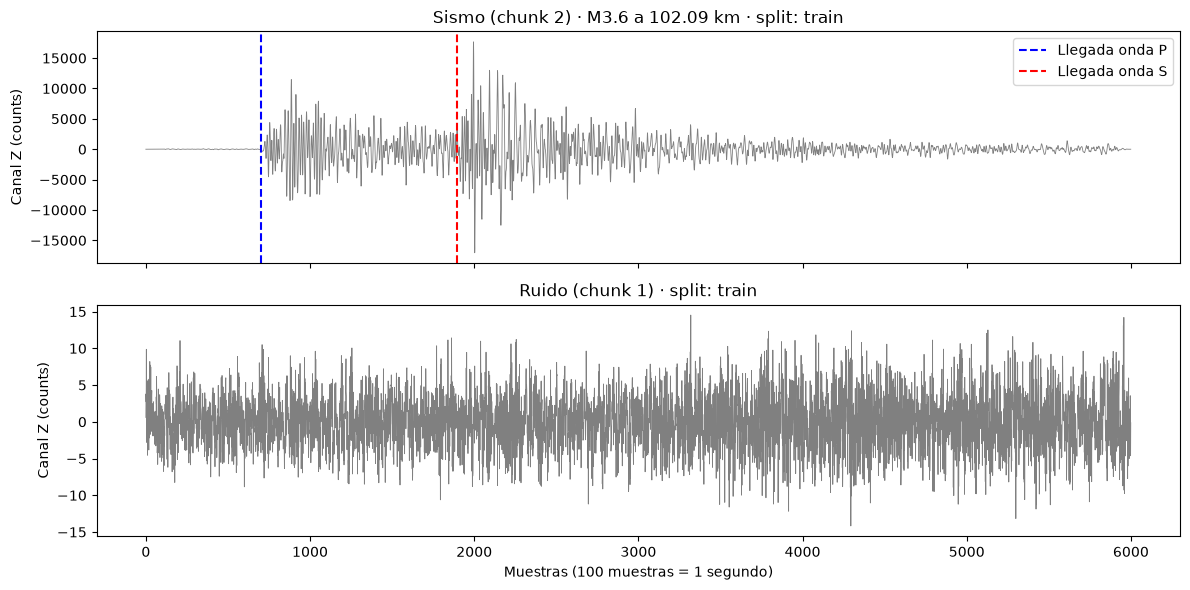

In [6]:
# Se cargan las trazas, canal Z

sismo = df[(df['chunk'] == 2) & (df['source_magnitude'] > 3)].iloc[0]
ruido = df[df['chunk'] == 1].iloc[0]
x_sismo = cargar(sismo['trace_name'], 2)
x_ruido = cargar(ruido['trace_name'], 1)
print('forma:', x_sismo.shape, x_ruido.shape, ' tipo:', x_sismo.dtype)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axes[0].plot(x_sismo[:, 2], color='gray', lw=0.6)
axes[0].axvline(sismo['p_arrival_sample'], color='blue', ls='--', label='Llegada onda P')
axes[0].axvline(sismo['s_arrival_sample'], color='red', ls='--', label='Llegada onda S')
axes[0].set_title(f"Sismo (chunk 2) · M{sismo['source_magnitude']} a {sismo['source_distance_km']} km · split: {sismo['split']}")
axes[0].legend(loc='upper right')
axes[1].plot(x_ruido[:, 2], color='gray', lw=0.6)
axes[1].set_title(f"Ruido (chunk 1) · split: {ruido['split']}")

for ax in axes:
    ax.set_ylabel('Canal Z (counts)')
axes[1].set_xlabel('Muestras (100 muestras = 1 segundo)')
plt.tight_layout()
plt.show()